<a href="https://colab.research.google.com/github/Bussy11/kogi-payroll-anomaly/blob/main/AI_PROJ.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CELL 1: IMPORT REQUIRED LIBRARIES
# PROJECT: AI PAYROLL ANOMALY DETECTION SYSTEM
# ============================================================

# pandas processes payroll tables and CSV files.
import pandas as pd

# numpy performs numerical calculations.
import numpy as np

# matplotlib creates charts.
import matplotlib.pyplot as plt

# IsolationForest detects unusual payroll records.
from sklearn.ensemble import IsolationForest

# train_test_split divides data into training and testing sets.
from sklearn.model_selection import train_test_split

# StandardScaler prepares numerical features for analysis.
from sklearn.preprocessing import StandardScaler

# Google Colab tools allow users to upload and download files.
from google.colab import files

# io helps read uploaded CSV files.
import io

# datetime records the date and time of the analysis.
from datetime import datetime

# Warnings are suppressed to keep the notebook output readable.
import warnings
warnings.filterwarnings("ignore")

# Display a confirmation message.
print("All required libraries have been imported successfully.")
print("AI Payroll Anomaly Detection System is ready.")

All required libraries have been imported successfully.
AI Payroll Anomaly Detection System is ready.


In [ ]:
# ============================================================
# CELL 2: WELCOME, AUTHORIZATION AND USER REGISTRATION
# PROJECT: AI PAYROLL ANOMALY DETECTION SYSTEM
# ============================================================

print("=" * 65)
print("       WELCOME TO AI PAYROLL ANOMALY DETECTION SYSTEM")
print("=" * 65)

print("\nKindly use our services with authorization.")
print("Please provide your details to begin your session.")

print("-" * 65)

# ------------------------------------------------------------
# STEP 1: REQUEST USER AUTHORIZATION
# ------------------------------------------------------------

authorization = input(
    "\nDo you have authorization to use this system? (YES/NO): "
).strip().upper()

# Stop the session if authorization is not confirmed.
if authorization not in ["YES", "Y"]:

    print("\n" + "=" * 65)
    print("ACCESS DENIED")
    print("Please obtain authorization before proceeding.")
    print("Thank you for your understanding.")
    print("=" * 65)

    raise RuntimeError("Authorization was not confirmed.")

# ------------------------------------------------------------
# STEP 2: COLLECT THE USER'S FULL NAME
# ------------------------------------------------------------

full_name = input(
    "\nKindly enter your full name: "
).strip()

# Validate the full name.
if not full_name:

    raise ValueError(
        "Full name is required. Please rerun this cell."
    )

# ------------------------------------------------------------
# STEP 3: COLLECT THE USER'S ADDRESS
# ------------------------------------------------------------

address = input(
    "Kindly enter your residential or official address: "
).strip()

# Validate the address.
if not address:

    raise ValueError(
        "Address is required. Please rerun this cell."
    )

# ------------------------------------------------------------
# STEP 4: COLLECT THE USER'S CONTACT NUMBER
# ------------------------------------------------------------

contact_number = input(
    "Kindly enter your contact number: "
).strip()

# Validate the contact number.
if not contact_number:

    raise ValueError(
        "Contact number is required. Please rerun this cell."
    )

# ------------------------------------------------------------
# STEP 5: DISPLAY THE REGISTRATION SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("             USER REGISTRATION SUCCESSFUL")
print("=" * 65)

print(f"Full Name      : {full_name}")
print(f"Address        : {address}")
print(f"Contact Number : {contact_number}")

print("-" * 65)
print("Authorization confirmed.")
print("Your session is ready to begin.")
print("Welcome to AI Payroll Anomaly Detection System!")
print("=" * 65)

       WELCOME TO AI PAYROLL ANOMALY DETECTION SYSTEM

Kindly use our services with authorization.
Please provide your details to begin your session.
-----------------------------------------------------------------


In [ ]:
# ============================================================
# CELL 3: UPLOAD CSV OR GENERATE SAMPLE PAYROLL DATA
# ============================================================

print("\nPAYROLL DATA OPTIONS")
print("1. Upload an existing payroll CSV file.")
print("2. Generate a sample payroll dataset.")

data_choice = input(
    "\nSelect option 1 or 2: "
).strip()

# ------------------------------------------------------------
# OPTION 1: UPLOAD AN EXTERNAL CSV FILE
# ------------------------------------------------------------

if data_choice == "1":

    print("\nSelect your payroll CSV file.")

    uploaded_files = files.upload()

    # Confirm that a file was uploaded.
    if not uploaded_files:
        raise ValueError("No CSV file was uploaded.")

    # Select the uploaded file.
    uploaded_filename = next(iter(uploaded_files))

    # Check that the uploaded file is a CSV.
    if not uploaded_filename.lower().endswith(".csv"):
        raise ValueError(
            "Please upload a file with the .csv extension."
        )

    # Read the uploaded CSV into a pandas DataFrame.
    df = pd.read_csv(
        io.BytesIO(uploaded_files[uploaded_filename])
    )

    print("\nFile uploaded successfully:")
    print(uploaded_filename)

# ------------------------------------------------------------
# OPTION 2: GENERATE SAMPLE PAYROLL DATA
# ------------------------------------------------------------

elif data_choice == "2":

    # Use a fixed random seed so the sample is reproducible.
    np.random.seed(42)

    # Generate 200 sample employee records.
    number_of_employees = 200

    # Generate employee identification numbers.
    employee_ids = [
        f"EMP{i:03d}"
        for i in range(1, number_of_employees + 1)
    ]

    # Generate sample employee names.
    employee_names = [
        f"Employee_{i:03d}"
        for i in range(1, number_of_employees + 1)
    ]

    # Generate state and local government area information.
    states = np.random.choice(
        ["Kogi", "Kwara", "Ekiti"],
        number_of_employees
    )

    lgas = np.random.choice(
        ["Okene", "Kabba", "Lokoja", "Ado"],
        number_of_employees
    )

    # Generate basic salaries.
    basic_salary = np.random.normal(
        80000, 12000, number_of_employees
    )

    # Generate allowances.
    allowances = np.random.normal(
        15000, 4000, number_of_employees
    )

    # Generate deductions.
    deductions = np.random.normal(
        5000, 1500, number_of_employees
    )

    # Ensure salary components are non-negative.
    basic_salary = np.maximum(basic_salary, 30000)
    allowances = np.maximum(allowances, 0)
    deductions = np.maximum(deductions, 0)

    # Calculate net salary from the salary components.
    net_salary = (
        basic_salary + allowances - deductions
    )

    # Create the payroll table.
    df = pd.DataFrame({
        "EmployeeID": employee_ids,
        "Name": employee_names,
        "State": states,
        "LGA": lgas,
        "BasicSalary": basic_salary.round(2),
        "Allowances": allowances.round(2),
        "Deductions": deductions.round(2),
        "NetSalary": net_salary.round(2)
    })

    # Insert two artificial unusual records for demonstration.
    # These are deliberately unusual and are not real employees.
    df.loc[10, "BasicSalary"] = 350000
    df.loc[10, "NetSalary"] = (
        df.loc[10, "BasicSalary"]
        + df.loc[10, "Allowances"]
        - df.loc[10, "Deductions"]
    )

    df.loc[25, "Allowances"] = 200000
    df.loc[25, "NetSalary"] = (
        df.loc[25, "BasicSalary"]
        + df.loc[25, "Allowances"]
        - df.loc[25, "Deductions"]
    )

    print("\nSample payroll dataset generated successfully.")

# ------------------------------------------------------------
# INVALID OPTION
# ------------------------------------------------------------

else:

    raise ValueError(
        "Invalid selection. Restart the cell and choose 1 or 2."
    )

# Display the dataset dimensions.
print("\nNumber of payroll records:", len(df))
print("Number of columns:", len(df.columns))

# Display the first five payroll records.
display(df.head())


PAYROLL DATA OPTIONS
1. Upload an existing payroll CSV file.
2. Generate a sample payroll dataset.

Select option 1 or 2: 1

Select your payroll CSV file.


Saving payroll_anomaly_results.csv to payroll_anomaly_results.csv

File uploaded successfully:
payroll_anomaly_results.csv

Number of payroll records: 1200
Number of columns: 12


,Employee_ID,LG,grade_level,Age,days_present,overtime_hours,Basic_Salary,Allowance,bank_account,Anomaly_Score,Anomaly_Prediction,Payroll_Status
0,KG200000,Bassa,15,47,20,6,155645.59,51022.33,9597492782,0.090269,1,Normal
1,KG200001,Ofu,7,49,20,1,85950.28,30857.37,8865326770,0.112670,1,Normal
2,KG200002,Kabba/Bunu,5,49,19,2,65147.51,25732.26,3769501980,0.102793,1,Normal
3,KG200003,Igalamela-Odolu,7,27,22,7,86739.36,26978.87,9375625448,0.099509,1,Normal
4,KG200004,Idah,10,30,22,7,112460.56,40221.54,2205860211,0.124189,1,Normal


In [ ]:
# ============================================================
# CELL 4: DATA CLEANING AND VALIDATION
# ============================================================

print("\nDATA CLEANING STARTED")
print("-" * 50)

# Remove spaces from the beginning and end of column names.
df.columns = df.columns.astype(str).str.strip()

# Remove duplicate column names if any exist.
df = df.loc[:, ~df.columns.duplicated()].copy()

# Display the original column names.
print("Available columns:")
print(df.columns.tolist())

# Remove completely empty rows.
df = df.dropna(how="all").copy()

# Convert numeric-looking columns into numeric values.
# This helps handle salary values stored as text.
for column in df.columns:

    if df[column].dtype == "object":

        cleaned_values = (
            df[column]
            .astype(str)
            .str.replace(",", "", regex=False)
            .str.replace("₦", "", regex=False)
            .str.strip()
        )

        converted_values = pd.to_numeric(
            cleaned_values,
            errors="coerce"
        )

        # Only convert a column if most non-empty values
        # can reasonably be interpreted as numbers.
        non_empty_count = df[column].notna().sum()

        if non_empty_count > 0:

            conversion_rate = (
                converted_values.notna().sum()
                / non_empty_count
            )

            if conversion_rate >= 0.80:
                df[column] = converted_values

# Identify missing values in each column.
missing_values = df.isnull().sum()

print("\nMissing values before final cleaning:")
display(missing_values.to_frame("MissingValues"))

# Report duplicate rows.
duplicate_count = df.duplicated().sum()

print("\nDuplicate rows found:", duplicate_count)

# Remove exact duplicate rows.
df = df.drop_duplicates().copy()

# Display the final dataset size.
print("\nDATA CLEANING COMPLETED")
print("Remaining records:", len(df))

# Stop if no records remain.
if df.empty:
    raise ValueError(
        "The dataset is empty after cleaning. Please upload a valid file."
    )

# Display the cleaned dataset.
display(df.head())


DATA CLEANING STARTED
--------------------------------------------------
Available columns:
['Employee_ID', 'LG', 'grade_level', 'Age', 'days_present', 'overtime_hours', 'Basic_Salary', 'Allowance', 'bank_account', 'Anomaly_Score', 'Anomaly_Prediction', 'Payroll_Status']

Missing values before final cleaning:


,MissingValues
Employee_ID,0
LG,0
grade_level,0
Age,0
days_present,0
overtime_hours,0
Basic_Salary,0
Allowance,0
bank_account,0
Anomaly_Score,0



Duplicate rows found: 0

DATA CLEANING COMPLETED
Remaining records: 1200


,Employee_ID,LG,grade_level,Age,days_present,overtime_hours,Basic_Salary,Allowance,bank_account,Anomaly_Score,Anomaly_Prediction,Payroll_Status
0,KG200000,Bassa,15,47,20,6,155645.59,51022.33,9597492782,0.090269,1,Normal
1,KG200001,Ofu,7,49,20,1,85950.28,30857.37,8865326770,0.112670,1,Normal
2,KG200002,Kabba/Bunu,5,49,19,2,65147.51,25732.26,3769501980,0.102793,1,Normal
3,KG200003,Igalamela-Odolu,7,27,22,7,86739.36,26978.87,9375625448,0.099509,1,Normal
4,KG200004,Idah,10,30,22,7,112460.56,40221.54,2205860211,0.124189,1,Normal


In [ ]:
# ============================================================
# CELL 5: FEATURE SELECTION AND TRAIN/TEST SPLIT
# ============================================================

print("\nPREPARING DATA FOR MACHINE LEARNING")
print("-" * 50)

# Identify numerical columns in the dataset.
numeric_columns = df.select_dtypes(
    include=[np.number]
).columns.tolist()

# Exclude columns that appear to be employee identifiers.
# IDs are not salary behaviour and should not drive predictions.
identifier_words = [
    "id",
    "employeeid",
    "staffid",
    "recordnumber"
]

feature_columns = [
    column
    for column in numeric_columns
    if column.lower() not in identifier_words
]

# Select columns containing useful numerical information.
X = df[feature_columns].copy()

# Remove infinite values.
X = X.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove features that contain no valid values.
X = X.dropna(
    axis=1,
    how="all"
)

# Update the list of features after removing empty columns.
feature_columns = X.columns.tolist()

# Require at least one usable numerical feature.
if len(feature_columns) == 0:
    raise ValueError(
        "No usable numerical columns were found. "
        "Your CSV should contain numerical payroll fields "
        "such as BasicSalary, Allowances, Deductions, "
        "or NetSalary."
    )

# Fill missing feature values using each column's median.
# This is a simple preparation method, not proof that
# the missing values are correct.
X = X.fillna(X.median())

# Remove columns that have the same value in every record.
varying_columns = X.columns[X.nunique() > 1].tolist()

X = X[varying_columns]

# Update the selected feature list.
feature_columns = X.columns.tolist()

# Stop if no variation remains.
if X.shape[1] == 0:
    raise ValueError(
        "The numerical features contain no variation. "
        "Upload a more informative payroll dataset."
    )

# Ensure there are enough records for training and testing.
if len(X) < 10:
    raise ValueError(
        "At least 10 payroll records are required "
        "for this demonstration."
    )

# Split the records into training and testing sets.
# 80% is used for training and 20% for testing.
X_train, X_test = train_test_split(
    X,
    test_size=0.20,
    random_state=42
)

# Learn the scaling parameters from training data only.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

# Apply the training scaler to the testing data.
X_test_scaled = scaler.transform(X_test)

print("Selected machine-learning features:")
print(feature_columns)

print("\nTotal records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining and testing data prepared successfully.")


PREPARING DATA FOR MACHINE LEARNING
--------------------------------------------------
Selected machine-learning features:
['grade_level', 'Age', 'days_present', 'overtime_hours', 'Basic_Salary', 'Allowance', 'bank_account', 'Anomaly_Score', 'Anomaly_Prediction']

Total records: 1200
Training records: 960
Testing records: 240

Training and testing data prepared successfully.


In [ ]:
# ============================================================
# CELL 6: TRAIN THE AI MODEL AND DETECT ANOMALIES
# ALGORITHM: ISOLATION FOREST
# ============================================================

print("\nTRAINING THE AI ANOMALY DETECTION MODEL")
print("-" * 50)

# Create the Isolation Forest model.
# contamination=0.05 means the model is configured to
# expect approximately 5% unusual records.
# This is a modelling assumption, not a verified fraud rate.
model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42
)

# Train the model using the training data only.
model.fit(X_train_scaled)

print("Model training completed successfully.")

# Score the held-out testing records.
# Lower decision scores generally indicate greater unusualness.
test_scores = model.decision_function(X_test_scaled)

# Predict whether each testing record is unusual.
# -1 means flagged as an anomaly.
#  1 means not flagged as an anomaly.
test_predictions = model.predict(X_test_scaled)

print("\nTesting data analysed:", len(X_test))
print(
    "Testing records flagged:",
    int((test_predictions == -1).sum())
)

# Apply the trained model to all available records.
# The model is not retrained on the complete dataset.
all_scaled = scaler.transform(X)

all_predictions = model.predict(all_scaled)

# Create a copy of the cleaned payroll data for reporting.
results = df.copy()

# Add anomaly prediction to each payroll record.
results["AnomalyStatus"] = np.where(
    all_predictions == -1,
    "Flagged for Review",
    "No Anomaly Flag"
)

# Add a continuous anomaly score.
results["AnomalyScore"] = model.decision_function(
    all_scaled
)

# Display the records flagged by the model.
flagged_records = results[
    results["AnomalyStatus"] == "Flagged for Review"
].copy()

print("\nMODEL ANALYSIS COMPLETED")

print("Total records analysed:", len(results))
print("Records flagged for review:", len(flagged_records))
print(
    "Records without an anomaly flag:",
    (results["AnomalyStatus"] == "No Anomaly Flag").sum()
)

print(
    "\nReminder: Flagged records require human investigation. "
    "They are not automatically fraudulent."
)

display(flagged_records.head(20))


TRAINING THE AI ANOMALY DETECTION MODEL
--------------------------------------------------
Model training completed successfully.

Testing data analysed: 240
Testing records flagged: 6

MODEL ANALYSIS COMPLETED
Total records analysed: 1200
Records flagged for review: 54
Records without an anomaly flag: 1146

Reminder: Flagged records require human investigation. They are not automatically fraudulent.


,Employee_ID,LG,grade_level,Age,days_present,overtime_hours,Basic_Salary,Allowance,bank_account,Anomaly_Score,Anomaly_Prediction,Payroll_Status,AnomalyStatus,AnomalyScore
17,KG200017,Idah,5,32,22,1,65227.35,88407.81,2098491719,-0.070678,-1,Flagged for Review,Flagged for Review,-0.031718
30,KG200030,Bassa,11,46,22,13,270882.54,43661.42,1788204968,-0.052036,-1,Flagged for Review,Flagged for Review,-0.029214
36,KG200036,Lokoja,15,24,20,13,157717.69,154770.92,7090474317,-0.152776,-1,Flagged for Review,Flagged for Review,-0.084568
76,KG200076,Ankpa,13,28,21,10,323320.08,41947.43,2324963941,-0.111832,-1,Flagged for Review,Flagged for Review,-0.040364
91,KG200091,Bassa,14,52,0,0,144667.11,55109.53,9400463222,0.059244,1,Normal,Flagged for Review,-0.006819
132,KG200132,Okehi,15,58,18,14,161511.95,61051.89,6279750937,-0.005833,-1,Flagged for Review,Flagged for Review,-0.011659
147,KG200147,Igalamela-Odolu,7,52,22,0,83723.82,77674.61,3927772408,-0.049872,-1,Flagged for Review,Flagged for Review,-0.016409
154,KG200154,Ofu,4,58,20,0,56405.20,54069.53,2982497292,-0.018793,-1,Flagged for Review,Flagged for Review,-0.007850
156,KG200156,Okene,11,57,19,5,118314.26,174517.97,2660102924,-0.156675,-1,Flagged for Review,Flagged for Review,-0.071277
181,KG200181,Okehi,6,48,22,13,189040.00,27011.94,8443282677,-0.021450,-1,Flagged for Review,Flagged for Review,-0.015936



GENERATING PAYROLL ANALYSIS CHART


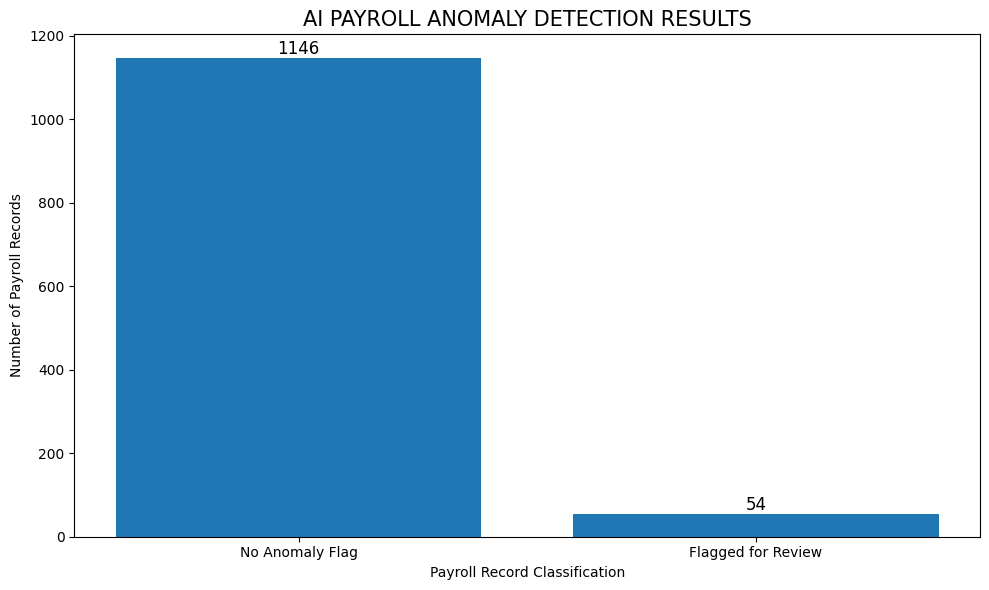


PAYROLL ANALYSIS SUMMARY
----------------------------------------
Total payroll records: 1200
Records flagged for review: 54
Percentage flagged: 4.5 %


In [ ]:
# ============================================================
# CELL 7: VISUALISE THE RESULTS
# ============================================================

print("\nGENERATING PAYROLL ANALYSIS CHART")

# Count records in each anomaly category.
status_counts = results["AnomalyStatus"].value_counts()

# Ensure both categories appear in the chart.
status_counts = status_counts.reindex(
    ["No Anomaly Flag", "Flagged for Review"],
    fill_value=0
)

# Create a bar chart.
plt.figure(figsize=(10, 6))

bars = plt.bar(
    status_counts.index,
    status_counts.values
)

# Add the number of records above each bar.
for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=12
    )

# Add the chart title and axis labels.
plt.title(
    "AI PAYROLL ANOMALY DETECTION RESULTS",
    fontsize=15
)

plt.xlabel("Payroll Record Classification")
plt.ylabel("Number of Payroll Records")

# Keep the chart layout readable.
plt.tight_layout()

# Display the chart.
plt.show()

# Display a short numerical summary.
print("\nPAYROLL ANALYSIS SUMMARY")
print("-" * 40)

print("Total payroll records:", len(results))

print(
    "Records flagged for review:",
    len(flagged_records)
)

print(
    "Percentage flagged:",
    round(
        len(flagged_records) / len(results) * 100,
        2
    ),
    "%"
)

In [ ]:
# ============================================================
# CELL 8: REPORT GENERATION AND DOWNLOAD
# ============================================================

print("\nANALYSIS COMPLETED SUCCESSFULLY.")

# Ask the user whether a report is required.
report_choice = input(
    "\nDo you need a downloadable report file? (YES/NO): "
).strip().upper()

# ------------------------------------------------------------
# OPTION 1: GENERATE AND DOWNLOAD THE REPORT
# ------------------------------------------------------------

if report_choice in ["YES", "Y"]:

    print("\nPreparing your payroll anomaly report...")

    # Record the report generation date and time.
    report_time = datetime.now().strftime(
        "%Y-%m-%d %H:%M:%S"
    )

    # Calculate the number and percentage of flagged records.
    total_records = len(results)

    flagged_count = len(flagged_records)

    flagged_percentage = (
        flagged_count / total_records * 100
        if total_records > 0
        else 0
    )

    # Create a summary report.
    summary = pd.DataFrame({
        "ReportItem": [
            "SystemName",
            "ReportDateTime",
            "UserContact",
            "TotalPayrollRecords",
            "TrainingRecords",
            "TestingRecords",
            "RecordsFlaggedForReview",
            "RecordsWithoutAnomalyFlag",
            "PercentageFlagged",
            "Algorithm",
            "SelectedFeatures",
            "ModelContaminationSetting",
            "Interpretation"
        ],

        "Value": [
            "AI Payroll Anomaly Detection System",
            report_time,
            contact_number,
            total_records,
            len(X_train),
            len(X_test),
            flagged_count,
            total_records - flagged_count,
            round(flagged_percentage, 2),
            "Isolation Forest",
            ", ".join(feature_columns),
            "5% expected anomaly proportion",
            "Flagged records require human investigation."
        ]
    })

    # Create a CSV file for the summary.
    summary_filename = "payroll_anomaly_summary.csv"

    summary.to_csv(
        summary_filename,
        index=False
    )

    # Create a CSV file containing every analysed record.
    results_filename = "payroll_anomaly_results.csv"

    results.to_csv(
        results_filename,
        index=False
    )

    # Create a separate CSV file containing flagged records.
    flagged_filename = "payroll_flagged_records.csv"

    flagged_records.to_csv(
        flagged_filename,
        index=False
    )

    # Create a separate testing-set results file.
    test_results = df.loc[X_test.index].copy()

    test_results["AnomalyStatus"] = np.where(
        test_predictions == -1,
        "Flagged for Review",
        "No Anomaly Flag"
    )

    test_results["AnomalyScore"] = test_scores

    testing_filename = "payroll_testing_results.csv"

    test_results.to_csv(
        testing_filename,
        index=False
    )

    # Package the report files into a single ZIP archive.
    import zipfile

    report_zip = "AI_Payroll_Anomaly_Report.zip"

    with zipfile.ZipFile(
        report_zip,
        "w",
        zipfile.ZIP_DEFLATED
    ) as zip_file:

        zip_file.write(
            summary_filename,
            arcname=summary_filename
        )

        zip_file.write(
            results_filename,
            arcname=results_filename
        )

        zip_file.write(
            flagged_filename,
            arcname=flagged_filename
        )

        zip_file.write(
            testing_filename,
            arcname=testing_filename
        )

    # Display the summary before downloading.
    print("\nREPORT SUMMARY")
    print("-" * 40)

    print("Total records:", total_records)
    print("Training records:", len(X_train))
    print("Testing records:", len(X_test))
    print("Records flagged:", flagged_count)
    print("Percentage flagged:", round(flagged_percentage, 2), "%")

    # Trigger the download immediately.
    print("\nYour report is ready. Download starting now...")

    files.download(report_zip)

    print("\nThank you for using AI Payroll Anomaly Detection System.")

# ------------------------------------------------------------
# OPTION 2: SKIP THE REPORT
# ------------------------------------------------------------

elif report_choice in ["NO", "N"]:

    print("\nYou have chosen not to download a report.")
    print("Your analysis is complete.")

    print(
        "\nGoodbye, and thank you for using our services."
    )

# ------------------------------------------------------------
# INVALID ANSWER
# ------------------------------------------------------------

else:

    print("\nInvalid selection.")

    print(
        "Please rerun this cell and answer YES or NO."
    )


ANALYSIS COMPLETED SUCCESSFULLY.

Do you need a downloadable report file? (YES/NO): Yes

Preparing your payroll anomaly report...

REPORT SUMMARY
----------------------------------------
Total records: 1200
Training records: 960
Testing records: 240
Records flagged: 54
Percentage flagged: 4.5 %

Your report is ready. Download starting now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Thank you for using AI Payroll Anomaly Detection System.


In [ ]:
# ============================================================
# CELL 9: INTERACTIVE PROJECT EXPLANATION ASSISTANT
# ============================================================

print("\nAI PAYROLL HELP ASSISTANT")
print("=" * 45)

print("You can ask questions about the system.")
print("Type EXIT when you want to leave the assistant.")

# Store explanations for common questions.
help_answers = {

    "algorithm":
        "The project uses Isolation Forest, an unsupervised "
        "machine-learning algorithm that identifies unusual "
        "numerical patterns in payroll records.",

    "isolation forest":
        "Isolation Forest identifies observations that can "
        "be separated from other observations relatively easily. "
        "Such records may be unusual and deserve investigation.",

    "training":
        "Training data is the portion of the dataset used to "
        "fit the machine-learning model. This project uses "
        "approximately 80 percent of the records for training.",

    "testing":
        "Testing data is held out during model fitting. "
        "This project uses approximately 20 percent of the "
        "records to examine the model's predictions on "
        "previously unseen records.",

    "accuracy":
        "This is an unsupervised anomaly-detection project. "
        "A defensible accuracy score requires independently "
        "verified labels identifying genuine anomalies. "
        "The percentage flagged is not model accuracy.",

    "csv":
        "CSV means Comma-Separated Values. It is a file format "
        "commonly used to store tabular data, including payroll "
        "records. You can upload a CSV file in Cell 3.",

    "anomaly":
        "An anomaly is a record that differs from the patterns "
        "learned by the model. It is not automatically fraud. "
        "A payroll officer should investigate flagged records.",

    "report":
        "The report includes the analysis summary, all analysed "
        "records, flagged records, and testing-set predictions. "
        "Run Cell 8 to generate and download the report.",

    "chart":
        "The bar chart compares the number of records flagged "
        "for review with the number not flagged by the model.",

    "contact":
        "The system collects a contact number at the beginning "
        "of the session. The number is included in the report "
        "summary. It is not independently verified.",

    "security":
        "The authorization prompt is a basic access check. "
        "It is not secure authentication. A production system "
        "should use verified accounts, role-based permissions, "
        "secure storage, and appropriate privacy controls.",

    "limitations":
        "The model detects unusual numerical patterns. It does "
        "not independently prove fraud, understand every payroll "
        "rule, or verify whether an employee is legally entitled "
        "to a payment.",

    "features":
        "Features are numerical columns used by the model. "
        "Examples include BasicSalary, Allowances, Deductions, "
        "and NetSalary, depending on the uploaded CSV.",

    "cleaning":
        "Data cleaning removes empty rows and exact duplicates, "
        "converts suitable numeric columns, and fills missing "
        "numerical feature values using medians."
}

# Start the question-and-answer loop.
while True:

    question = input("\nYour question: ").strip().lower()

    # End the help session if requested.
    if question in ["exit", "quit", "bye"]:

        print(
            "\nThank you for using the project explanation assistant."
        )

        break

    # Find a matching explanation.
    matched = False

    for keyword, explanation in help_answers.items():

        if keyword in question:

            print("\nEXPLANATION:")
            print(explanation)

            matched = True

            break

    # Provide a response if no matching topic is found.
    if not matched:

        print(
            "\nI do not have a prepared answer for that question."
        )

        print(
            "Try asking about the algorithm, training, testing, "
            "accuracy, CSV, anomaly, report, chart, security, "
            "cleaning, features, or limitations."
        )


AI PAYROLL HELP ASSISTANT
You can ask questions about the system.
Type EXIT when you want to leave the assistant.

Your question: How accurate is this report?

EXPLANATION:
The report includes the analysis summary, all analysed records, flagged records, and testing-set predictions. Run Cell 8 to generate and download the report.

Your question: Exit

Thank you for using the project explanation assistant.
